# Building a Research Assistant using RAG

### Learning Objectives

- Explain what Retrieval Augmented Generation (RAG) is
- Understand embeddings and semantic search
- Build a document retrieval system
- Create a chatbot for scientific literature
- Evaluate strengths and limitations of RAG

# 1. Why Do We Need RAG?

Large Language Models (LLMs) are powerful but may not know your own publications or the latest papers.

Retrieval-Augmented Generation (RAG) is an AI framework that connects a LLM to external knowledge sources before generating an answer.

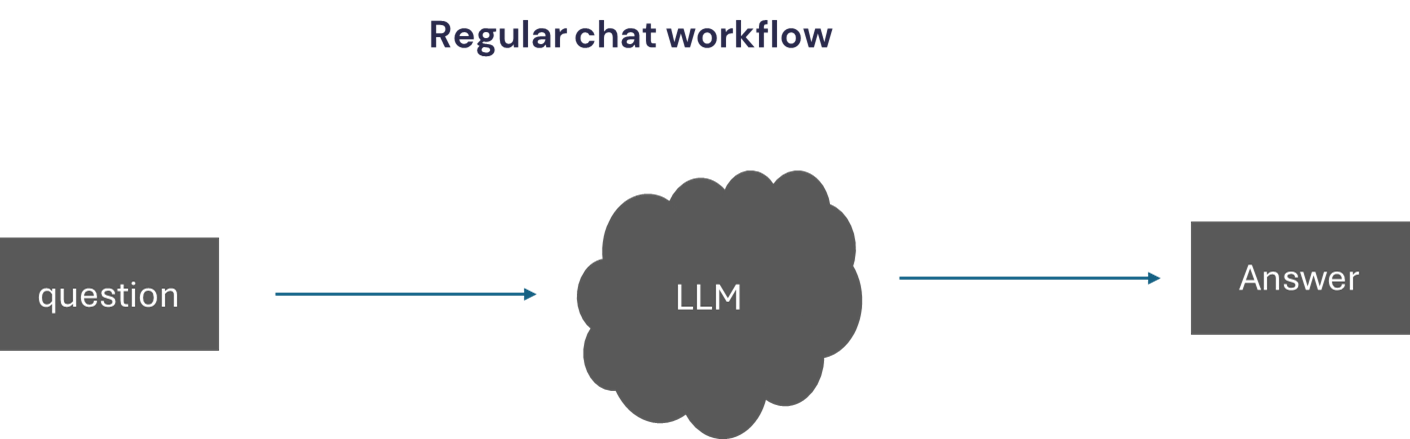

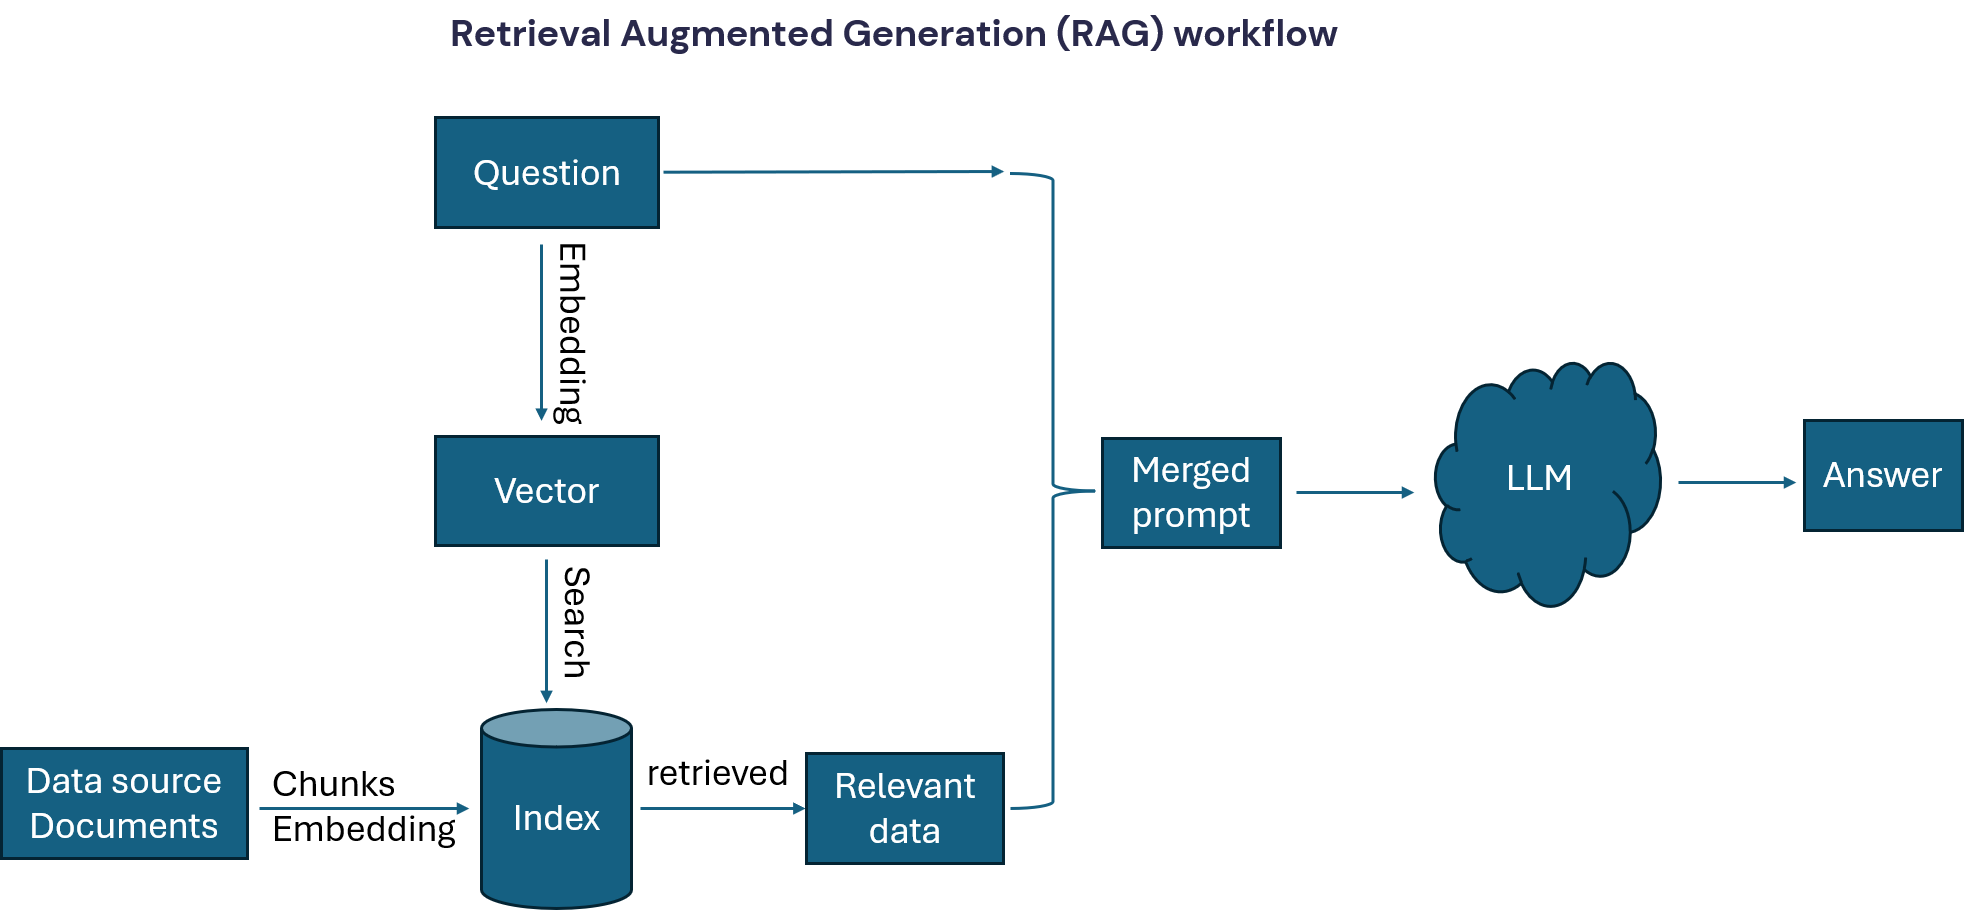

# 2. Install all packages

In [2]:
!pip install -q llama-index
!pip install -q llama-index-llms-langchain
!pip install -q llama-index-readers-file
!pip install -q llama-index-llms-openai-like

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
llama-index 0.14.25 requires llama-index-llms-openai<0.8,>=0.7.0, but you have llama-index-llms-openai 0.8.3 which is incompatible.


# 3. UF AI Gateway

## 3.1 Navigator Toolkit

https://navigator.ai.ufl.edu/ai-services/navigator-ai-toolkit/

## 3.2 Save the obtained API key to Colab's "Secrets"

You can use Colab's built-in "Secrets" feature to store sensitive information like API keys. These secrets are securely stored and can be accessed without directly editing a file.

* Navigate to the "Secrets" pane from the left navigation bar in Colab.
* Add a new secret with a name and value.
* Enable "Notebook access" for the current notebook.
* Access the secret using code:

`from google.colab import userdata`

`my_secret_value = userdata.get('secretName')`

In [3]:
from google.colab import userdata
import os

UF_API_KEY = userdata.get('API_key')

# Set as the environment variable, for OpenAI to automatically detect keys
os.environ['OPENAI_API_KEY'] = UF_API_KEY

## 3.3 Check list of available models

In [4]:
import openai

# Check list of available models
client = openai.OpenAI(
    # api_key=UF_API_KEY,
    base_url="https://api.ai.it.ufl.edu/"
)

response = client.models.list()

# Print available models in better format
for model in response:
    print(model.id)

flux.1-dev
flux.1-schnell
flux.2-klein
gemma-4-31b-it
gpt-oss-120b
gpt-oss-20b
granite-3.3-8b-instruct
kokoro
llama-3.3-70b-instruct
medgemma-27b-it
meta-muse-glimmer-30b
mistral-small-3.1
nemotron-3-nano-30b-a3b
nemotron-3-super-120b-a12b
nomic-embed-text-v1.5
sfr-embedding-mistral
whisper-large-v3


# 4. Download sample documents

In [5]:
import gdown
# The URL of the shared Google Drive folder
url = "https://drive.google.com/drive/folders/1zPL5hDzDsf5p9WgWF-4FLeBNu4B6DAod?usp=sharing"
url2 = "https://drive.google.com/drive/folders/1-_24-y9N2miNx-FLwidtaalnh1X0IZx3?usp=sharing" # Avartar

# Download the folder to your current working directory
downloaded_file_paths = gdown.download_folder(url, quiet=True, use_cookies=False)
downloaded_file_paths2 = gdown.download_folder(url2, quiet=True, use_cookies=False)

In [6]:
doc_path = os.path.dirname(downloaded_file_paths[0])
doc_path

'/content/docs_sap54'

# 5. Understanding Ebeddings(review)

Embeddings translate text into a series of **numbers**, creating a conceptual map where words or sentences with similar meanings are placed close together.

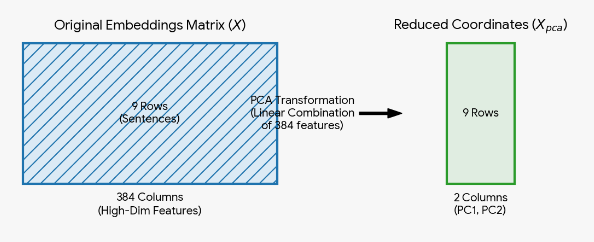

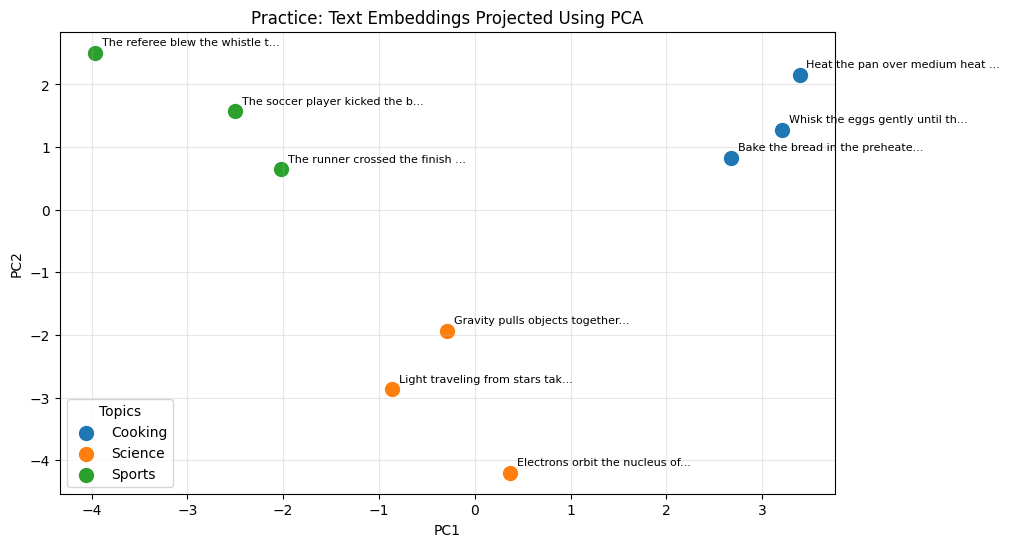

# 6. Build the Index

In [7]:
import os
import asyncio
from pathlib import Path
from typing import List

import httpx
import gradio as gr

from llama_index.core import (
    SimpleDirectoryReader,
    VectorStoreIndex,
    Settings,
    PromptHelper,
    StorageContext,
    load_index_from_storage,
)

from llama_index.core.embeddings import BaseEmbedding
from llama_index.core.node_parser import SentenceSplitter
from llama_index.llms.openai_like import OpenAILike


In [8]:
# two directories

PERSIST_DIR = "./index_storage"
DATA_DIR = "/content/docs_sap54"  # Change to your document directory


## 6.1 customize the embedding class

In [9]:
# Custom Embedding Model

class SFRMistralEmbedding(BaseEmbedding):
    """
    OpenAI-compatible embedding wrapper for
    UF AI Gateway embedding endpoint.
    """

    model_name: str
    api_base: str
    api_key: str

    def __init__(
        self,
        model_name: str,
        api_base: str,
        api_key: str,
        **kwargs,
    ):
        super().__init__(
            model_name=model_name,
            api_base=api_base.rstrip("/"),
            api_key=api_key,
            **kwargs,
        )

        self._headers = {
            "Authorization": f"Bearer {api_key}",
            "Content-Type": "application/json",
        }

        self._client = httpx.Client(
            timeout=60.0
        )

    # REAL WORK
    # ========================================================
    def _get_embedding(self, text: str) -> List[float]:
        payload = {
            "model": self.model_name,
            "input": [text],
        }

        response = self._client.post(
            f"{self.api_base}/embeddings",
            json=payload,
            headers=self._headers,
        )

        response.raise_for_status()

        return response.json()["data"][0]["embedding"]


    # Required by Lamma_index
    # ========================================================
    def _get_query_embedding(
        self,
        query: str,
    ) -> List[float]:
        return self._get_embedding(query)

    def _get_text_embedding(
        self,
        text: str,
    ) -> List[float]:
        return self._get_embedding(text)

    async def _aget_query_embedding(
        self,
        query: str,
    ) -> List[float]:
        loop = asyncio.get_running_loop()
        return await loop.run_in_executor(
            None,
            self._get_query_embedding,
            query,
        )

    async def _aget_text_embedding(
        self,
        text: str,
    ) -> List[float]:
        loop = asyncio.get_running_loop()
        return await loop.run_in_executor(
            None,
            self._get_text_embedding,
            text,
        )

    def get_query_embedding(
        self,
        query: str,
    ) -> List[float]:
        return self._get_query_embedding(query)

    def get_text_embedding(
        self,
        text: str,
    ) -> List[float]:
        return self._get_text_embedding(text)


## 6.2 Instantiate the embedding model

In [10]:
# Embedding Model
embed_model = SFRMistralEmbedding(
    model_name="sfr-embedding-mistral", # nomic-embed-text-v1.5
    api_base="https://api.ai.it.ufl.edu/v1",
    api_key=UF_API_KEY,
)

# Register embedding model to llama_index
# 1) Default using it whenever needs embedding
# 2) keep indexing and querying using the same embedding model
Settings.embed_model = embed_model


## 6.3 Split documents into chuncks

In [11]:
# Spliting Configuration
text_splitter = SentenceSplitter(
    chunk_size=512,
    chunk_overlap=50,
)

# Register spliter to llama_index
Settings.text_splitter = text_splitter

In [12]:
# verifying the chunking
documents = SimpleDirectoryReader(DATA_DIR).load_data()
nodes = text_splitter.get_nodes_from_documents(documents)

# check the first 2 chunks
for i, node in enumerate(nodes[:2]):
    print("="*80)
    print(f"Chunk {i}: {node.text}")

Chunk 0: Phytoplasma Effector SAP54 Induces Indeterminate
Leaf-Like Flower Development in
Arabidopsis Plants 1[C][W][OA]
Allyson M. MacLean 2, Akiko Sugio 2, Olga V . Makarova, Kim C. Findlay, Victoria M. Grieve, Re ´ka To´ th,
Mogens Nicolaisen, and Saskia A. Hogenhout*
Department of Disease and Stress Biology (A.M.M., A.S., V .M.G., S.A.H.) and Bio-Imaging Facility (K.C.F.),
John Innes Centre, Norwich NR4 7UH, United Kingdom; Department of Agroecology , Faculty of Science and
Technology , Aarhus University , Slagelse DK–4200, Denmark (O.V .M., M.N.); and Max Planck Institute for
Plant Breeding Research, 50829 Cologne, Germany (R.T.)
Phytoplasmas are insect-transmitted bacterial plant pathogens that cause considerable damage to a diverse range of agri-
cultural crops globally . Symptoms induced in infected plants suggest that these phytopathogens may modulate developmental
processes within the plant host. We report herein that Aster Yellows phytoplasma strain Witches’ Broom (A Y-WB) r

## 6.4 building index

In [13]:
# Index Construction from documents
# ============================================================
def construct_index(directory_path: str):
    # load documents
    documents = SimpleDirectoryReader(directory_path).load_data()

    # VectorStoreIndex converts each document into embeddings (using the registered embed_model)
    # stores them in a vector database for semantic search and retrieval
    index = VectorStoreIndex.from_documents(documents)

    # Persist the index to disk for later reuse
    index.storage_context.persist(persist_dir=PERSIST_DIR)

    return index


# Load Existing Index or Build New One
# ============================================================

def get_index():

    persist_path = Path(PERSIST_DIR)

    if persist_path.exists():
        print("Loading existing index...")

        storage_context = StorageContext.from_defaults(
            persist_dir=PERSIST_DIR
        )

        return load_index_from_storage(
            storage_context
        )

    print("Creating new index...")

    return construct_index(DATA_DIR)

In [14]:
# Create/load once at startup
index = get_index() # this is a key step!

Creating new index...


## 6.5 (optional): what's retrieved?

In [24]:
query = "What are the key features of SAP54?"
retrieved_nodes = index.as_retriever().retrieve(query)

print(f"{len(retrieved_nodes)} relevant chunks were retrieved:" )

for i, node in enumerate(retrieved_nodes, 1): # sets the start index (or starting number) of the counter to 1 instead of the default 0
    print(
        f"\nChunk {i}"
    )
    print(
        f"Semantic similarity score: {node.score:.4f}"
    )
    print(node.text)


2 relevant chunks were retrieved:

Chunk 1
Semantic similarity score: 0.6540
SAP54 encodes a 10.7-kD protein having no homology
with previously characterized proteins or domains.
We examined available sequence data to identify ho-
mologs of this A Y-WB effector and performed align-
ments to compare the proteins. SAP54 homologs are
encoded in the genomes of at least three other phyto-
plasmas (Supplemental Fig. S11), two of which are mem-
bers of the A Y group of phytoplasmas (Onion Yellows
phytoplasma strain OY-M and MD Aster Yellows;
16SrI-B), while Spiraea stunt phytoplasma ( Candidatus
Phytoplasma pruni; 16SrIII, X-disease group) is dis-
tantly related to the A Y phytoplasmas. A Y phytoplas-
mas (particularly members of the 16SrI-A and 16SrI-B
subgroups) frequently elicit symptoms of abnormal
ﬂoral development (Lee et al., 2004); thus, the presence
of SAP54 homologs in representatives of this group is
not surprising. Although we were unable to identify
SAP54 homologs in a number of 

# 7 Build the chatbot

## 7.1 LLM Configuration

In [19]:
# Prompt Configuration
prompt_helper = PromptHelper(
    context_window=8192, # The maximum input prompt (context + query + instructions) tokens the LLM can handle
    num_output=1024, # Maximum number of tokens in the model’s answer.
    chunk_overlap_ratio=0.10,
    chunk_size_limit=1024,
)


# Specify a LLM
llm = OpenAILike(
    model="llama-3.3-70b-instruct", # gpt-oss-120b, llama-3.3-70b-instruct
    api_base="https://api.ai.it.ufl.edu/v1",
    api_key=UF_API_KEY,
    temperature=0.7, # range 0-2. Lower values: more precise, repeatable answers. Higher values: more imaginative, but less reliable.
    max_tokens=1024,
    context_window=8192,
)

# Register the LLM and prompt_helper to llama_index
Settings.llm = llm
Settings.prompt_helper = prompt_helper

## 7.2 Define the Chat Function

In [21]:
# Chat Function
def chatbot(message, history):

    """
    message is the current user input/question
    history is the chat history
    return is the bot's response
    """

    recent_history = history[-6:]  # last 3 exchanges

    conv_context = ""

    for msg in recent_history:

        role = msg["role"]
        content = msg["content"]

        if role == "user":
            conv_context += f"\nUser: {content}"
        elif role == "assistant":
            conv_context += f"\nAssistant: {content}"

    question = f"""
        Conversation context:
        {conv_context}

        Current user question:
        {message}
        """

    # Create a query engine from the index
    # The query_engine handles retrieval + response generation
    query_engine = index.as_query_engine(
        similarity_top_k=5, # only use top 5 retrieved data scourecs
        response_mode="compact", # response_mode="compact" means answers will be concise rather than verbose
    )

    # Run a query against the index
    # This takes the user input, retrieves relevant context from the index
    # merges it into a prompt, and sends it to the LLM for an answer
    response = query_engine.query(question)

    return str(response)

## 7.3 Chat interface via Gradio

In [20]:
# Gradio UI
chatbot_component = gr.Chatbot(
    height=700,
    avatar_images=(
        "/content/avatar/user.png",
        "/content/avatar/robot.png"
    ),
)

demo = gr.ChatInterface(
    fn=chatbot,
    chatbot=chatbot_component,
    title="Plant Pathogen RAG Assistant",
    description="Ask questions about indexed papers."
)


# Launch
demo.launch(
    server_name="0.0.0.0",
    server_port=7860,
    debug=True
)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://225c1fa21a6816b006.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 0.0.0.0:7860 <> https://225c1fa21a6816b006.gradio.live


# 8. RAG vs No-RAG Comparison

In [31]:
# --------------------------------------------------
# No-RAG Chatbot
# --------------------------------------------------
def chatbot_norag(message, history):
    """
    Direct LLM chat without document retrieval.
    Useful for comparing against RAG.
    """

    recent_history = history[-6:]

    conv_context = ""

    for msg in recent_history:

        role = msg["role"]
        content = msg["content"]

        if role == "user":
            conv_context += f"\nUser: {content}"

        elif role == "assistant":
            conv_context += f"\nAssistant: {content}"

    prompt = f"""
You are a helpful research assistant.

Conversation history:
{conv_context}

Current user question:
{message}

Answer:
"""

    response = llm.complete(prompt)

    return str(response)

In [34]:
with gr.Blocks() as demo:

    gr.Markdown("# RAG vs No-RAG Comparison")

    chatbot = gr.ChatInterface(
        fn=chatbot,
        title="RAG Assistant"
    )

    chatbot2 = gr.ChatInterface(
        fn=chatbot_norag,
        title="LLM Only"
    )

In [35]:
# Launch
demo.launch(
    server_name="0.0.0.0",
    server_port=7860,
    debug=True
)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://17ba905ee180c9477f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 0.0.0.0:7860 <> https://17ba905ee180c9477f.gradio.live


# 9. Strengths and Limitations of RAG

## Strengths of RAG

- **Improved Factual Accuracy**
  - Grounds responses in retrieved source documents.
  - Significantly reduces LLM hallucinations.

- **Access to Up-to-Date Information**
  - Retrieves newly added or real-time information at query time.
  - Eliminates the need to retrain or fine-tune the model for every knowledge update.

- **Domain Adaptability**
  - Enables organizations to connect private documents, manuals, reports, policies, and knowledge bases.
  - Avoids the cost and complexity of custom model training.

- **Source Attribution and Transparency**
  - Provides citations or references to retrieved text.
  - Increases user trust, particularly in healthcare, legal, financial, and scientific applications.

---

## Limitations of RAG

- **Dependency on Retrieval Quality**
  - The quality of the answer depends heavily on the quality of retrieved documents.
  - Poor retrieval leads to poor answers ("garbage in, garbage out").

- **Context Loss from Document Chunking**
  - Large documents are split into smaller chunks before indexing.
  - Important relationships across sections may be lost.

- **Over-Retrieval and Noise**
  - Irrelevant or loosely related chunks may be retrieved.
  - Excessive context can distract the LLM and reduce answer quality.

- **Complex Reasoning Bottlenecks**
  - Traditional RAG systems excel at retrieval but may struggle with:
    - Multi-hop reasoning
    - Cross-document synthesis
    - Mathematical calculations
    - Complex table interpretation

